# View TAZ trip matrices

Loads the OMX file at `paths.taz_trips_omx` in `settings.yaml` and summarises each matrix:
totals, intrazonal share, trip ends by zone, largest OD pairs, and a few plots.

In [1]:
# Imports and config

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import openmatrix as omx
import pandas as pd
from config import load_settings

settings = load_settings()
omx_path = settings['paths']['t171_2020_taz_trips_omx']

# Fixed colors per matrix so work / non-work look the same in every plot
MATRIX_COLORS = {'work': '#2a78d6', 'non-work': '#eb6834'}

pd.options.display.float_format = '{:,.1f}'.format

In [2]:
# Load all matrices into memory and close the file

f = omx.open_file(omx_path, 'r')
try:
    print(f"File     : {omx_path}")
    print(f"Shape    : {f.shape()}")
    print(f"Matrices : {f.list_matrices()}")
    print(f"Mappings : {f.list_mappings()}")

    matrices = {name: np.asarray(f[name][:], dtype=np.float64) for name in f.list_matrices()}

    if f.list_mappings():
        map_name = f.list_mappings()[0]
        zone_to_idx = f.mapping(map_name)
        zones = np.array(sorted(zone_to_idx, key=zone_to_idx.get))
    else:
        zones = np.arange(1, f.shape()[0] + 1)
finally:
    f.close()

matrices['total'] = sum(matrices.values())
zone_index = pd.Index(zones, name='zone')
print(f"Zones    : {len(zones):,} ({zones.min()} .. {zones.max()})")

File     : /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/T171_2020_OMX/taz_trips.omx
Shape    : (np.int32(5922), np.int32(5922))
Matrices : ['non-work', 'work']
Mappings : ['zone number']
Zones    : 5,922 (1 .. 5922)


In [3]:
# Summary per matrix

def summarize(m):
    total = m.sum()
    intrazonal = np.trace(m)
    return {
        'total trips': total,
        'intrazonal': intrazonal,
        'intrazonal %': 100 * intrazonal / total if total else np.nan,
        'nonzero cells': int(np.count_nonzero(m)),
        'nonzero %': 100 * np.count_nonzero(m) / m.size,
        'max cell': m.max(),
        'negative cells': int((m < 0).sum()),
        'NaN cells': int(np.isnan(m).sum()),
    }

summary = pd.DataFrame({name: summarize(m) for name, m in matrices.items()}).T
summary

,total trips,intrazonal,intrazonal %,nonzero cells,nonzero %,max cell,negative cells,NaN cells
non-work,"1,568,912.0","44,620.0",2.8,"898,484.0",2.6,"1,921.0",0.0,0.0
work,"1,064,394.0","4,930.0",0.5,"714,244.0",2.0,97.0,0.0,0.0
total,"2,633,306.0","49,550.0",1.9,"1,504,107.0",4.3,"1,921.0",0.0,0.0


In [4]:
# Trip ends by zone (origins = row sums, destinations = column sums)

trip_ends = pd.DataFrame(
    {f'{name} {kind}': (m.sum(axis=1) if kind == 'orig' else m.sum(axis=0))
     for name, m in matrices.items() for kind in ('orig', 'dest')},
    index=zone_index,
)
print(f"Zones with no total origins     : {(trip_ends['total orig'] == 0).sum():,}")
print(f"Zones with no total destinations: {(trip_ends['total dest'] == 0).sum():,}")
trip_ends.describe().T

Zones with no total origins     : 7
Zones with no total destinations: 0


,count,mean,std,min,25%,50%,75%,max
non-work orig,"5,922.0",264.9,739.0,0.0,16.2,71.0,233.0,"27,237.0"
non-work dest,"5,922.0",264.9,396.4,1.0,70.0,156.0,321.0,"10,765.0"
work orig,"5,922.0",179.7,223.7,0.0,27.0,95.0,250.0,"1,916.0"
work dest,"5,922.0",179.7,430.0,0.0,15.0,58.0,174.0,"12,099.0"
total orig,"5,922.0",444.7,795.0,0.0,93.0,230.0,525.8,"27,237.0"
total dest,"5,922.0",444.7,792.9,1.0,102.0,233.0,493.8,"22,864.0"


In [5]:
# Top zones by origins and by destinations

TOP_N = 20
pd.concat(
    {
        'top origins': trip_ends['total orig'].nlargest(TOP_N).reset_index(),
        'top destinations': trip_ends['total dest'].nlargest(TOP_N).reset_index(),
    },
    axis=1,
)

top origins            top destinations           
          zone total orig             zone total dest
0         3388   27,237.0             3388   22,864.0
1          297   12,073.0               87   11,509.0
2          554   10,384.0             1133   11,451.0
3           87    9,775.0              302   10,016.0
4         1133    9,275.0             1317    9,535.0
5          303    9,275.0              554    9,269.0
6          547    9,055.0             2321    8,911.0
7          302    8,927.0             2518    8,592.0
8          248    8,799.0              248    8,452.0
9          346    7,932.0              297    8,430.0
10        2321    7,650.0               61    8,399.0
11          61    7,634.0             1583    8,181.0
12        1317    7,377.0              303    7,706.0
13        2518    7,067.0              547    7,065.0
14        2329    6,860.0             2329    6,849.0
15         548    6,575.0             2164    6,758.0
16          85    6,450.0             2336    6,668.0
17         287    6,110.0              346    6,517.0
18         246    6,108.0              246    6,399.0
19         347    6,073.0             2517    6,242.0

In [6]:
# Largest OD pairs for a matrix

def top_od(name, n=20):
    m = matrices[name]
    flat = np.argpartition(m.ravel(), -n)[-n:]
    o, d = np.unravel_index(flat, m.shape)
    out = pd.DataFrame({'origin': zones[o], 'destination': zones[d], 'trips': m[o, d]})
    return out.sort_values('trips', ascending=False, ignore_index=True)

top_od('total')

,origin,destination,trips
0,3388,3388,"1,921.0"
1,302,302,"1,215.0"
2,297,297,980.0
3,87,87,942.0
4,1317,1317,810.0
5,2518,2518,746.0
6,297,303,689.0
7,248,248,641.0
8,61,61,601.0
9,303,303,561.0


In [7]:
# Look up a single zone: trips to/from it in each matrix, plus its top partners

def zone_view(zone, n=10):
    i = zone_to_idx[zone] if 'zone_to_idx' in globals() else int(np.where(zones == zone)[0][0])
    row = pd.DataFrame({
        name: {'origins': m[i].sum(), 'destinations': m[:, i].sum(), 'intrazonal': m[i, i]}
        for name, m in matrices.items()
    }).T
    display(row)
    display(pd.concat(
        {
            'top destinations from this zone': pd.Series(matrices['total'][i], index=zone_index).nlargest(n).reset_index(),
            'top origins to this zone': pd.Series(matrices['total'][:, i], index=zone_index).nlargest(n).reset_index(),
        },
        axis=1,
    ))

zone_view(zones[0])

,origins,destinations,intrazonal
non-work,60.0,105.0,2.0
work,77.0,43.0,0.0
total,137.0,148.0,2.0


top destinations from this zone     top origins to this zone    
                             zone   0                     zone   0
0                            5920 9.0                     5920 8.0
1                            5909 9.0                     5896 7.0
2                            5907 6.0                     5895 5.0
3                            5905 5.0                     5905 4.0
4                            5919 4.0                     5882 4.0
5                            5916 4.0                     5878 4.0
6                            5896 4.0                     5915 3.0
7                            5906 3.0                     5884 3.0
8                            5922 2.0                     5643 3.0
9                            5915 2.0                     4472 3.0

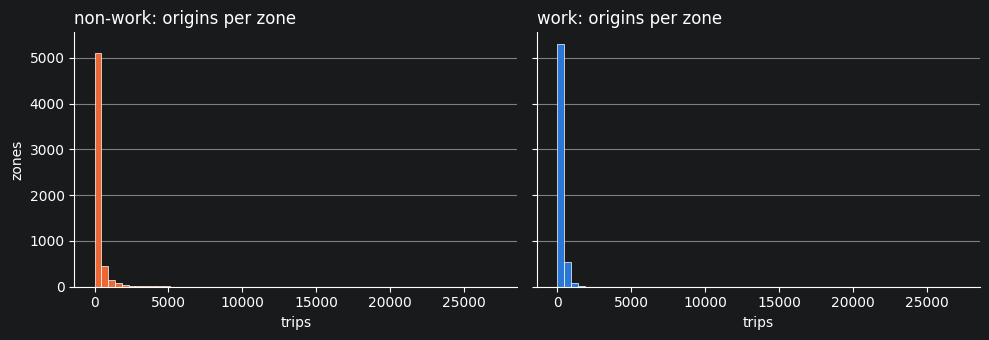

In [8]:
# Distribution of origins per zone, one panel per matrix (shared x for comparison)

names = [n for n in matrices if n != 'total']
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 3.5), sharex=True, sharey=True)
bins = np.linspace(0, trip_ends[[f'{n} orig' for n in names]].to_numpy().max(), 60)
for ax, name in zip(np.atleast_1d(axes), names):
    ax.hist(trip_ends[f'{name} orig'], bins=bins, color=MATRIX_COLORS.get(name, '#2a78d6'),
            edgecolor='white', linewidth=0.5)
    ax.set_title(f'{name}: origins per zone', loc='left')
    ax.set_xlabel('trips')
    ax.grid(axis='y', color='#e5e5e2', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel('zones')
fig.tight_layout()

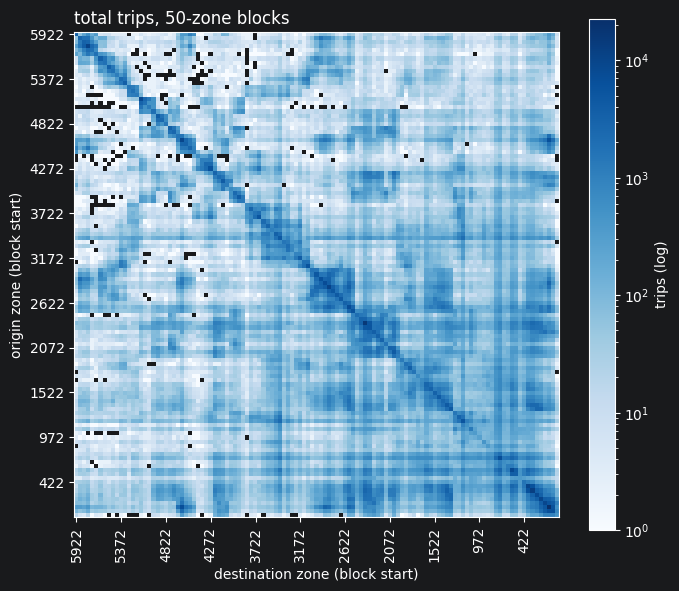

In [9]:
# Total matrix, aggregated into blocks of consecutive zones (log color scale)

BLOCK = 50  # zones per block
name = 'total'
m = matrices[name]
nb = int(np.ceil(len(zones) / BLOCK))
padded = np.zeros((nb * BLOCK, nb * BLOCK))
padded[:m.shape[0], :m.shape[1]] = m
blocks = padded.reshape(nb, BLOCK, nb, BLOCK).sum(axis=(1, 3))

fig, ax = plt.subplots(figsize=(7, 6))
img = ax.imshow(np.ma.masked_less_equal(blocks, 0), cmap='Blues',
                norm=plt.matplotlib.colors.LogNorm(), interpolation='nearest')
ticks = np.arange(0, nb, max(1, nb // 10))
ax.set_xticks(ticks, zones[np.minimum(ticks * BLOCK, len(zones) - 1)], rotation=90)
ax.set_yticks(ticks, zones[np.minimum(ticks * BLOCK, len(zones) - 1)])
ax.set_xlabel('destination zone (block start)')
ax.set_ylabel('origin zone (block start)')
ax.set_title(f'{name} trips, {BLOCK}-zone blocks', loc='left')
fig.colorbar(img, ax=ax, label='trips (log)')
fig.tight_layout()